In [19]:
import pandas as pd
import os
from google.colab import userdata
from itertools import combinations
import matplotlib.pyplot as plt
import time
import numpy as np

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
!kaggle datasets download -d harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows --unzip

Dataset URL: https://www.kaggle.com/datasets/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows
License(s): CC0-1.0
100% 175k/175k [00:00<00:00, 85.5MB/s]



In [20]:
!kaggle datasets download -d harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows --unzip

Dataset URL: https://www.kaggle.com/datasets/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows
License(s): CC0-1.0
100% 175k/175k [00:00<00:00, 105MB/s]



In [21]:
df = pd.read_csv("imdb_top_1000.csv")
print(df.shape) #1k row, 16 col
print(df.columns)
print(df.head())


(1000, 16)
Index(['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate',
       'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director',
       'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross'],
      dtype='object')
                                         Poster_Link  \
0  https://m.media-amazon.com/images/M/MV5BMDFkYT...   
1  https://m.media-amazon.com/images/M/MV5BM2MyNj...   
2  https://m.media-amazon.com/images/M/MV5BMTMxNT...   
3  https://m.media-amazon.com/images/M/MV5BMWMwMG...   
4  https://m.media-amazon.com/images/M/MV5BMWU4N2...   

               Series_Title Released_Year Certificate  Runtime  \
0  The Shawshank Redemption          1994           A  142 min   
1             The Godfather          1972           A  175 min   
2           The Dark Knight          2008          UA  152 min   
3    The Godfather: Part II          1974           A  202 min   
4              12 Angry Men          1957           U   96 min   

               

In [22]:
#Quality check of DF
star_columns = df[['Star1',"Star2","Star3","Star4"]]
print(star_columns.isna().sum()) #0 null in start columns
print("# of duplicate stars in same movie",(star_columns.nunique(axis=1) < 4).sum())
print(star_columns[star_columns.nunique(axis=1) < 4]) #for 4 movies, there are duplicate stars
#duplicate film check on title
print("duplicate film titles",df['Series_Title'].duplicated().sum()) #1
print(df[df['Series_Title'].duplicated(keep=False)]) #seems duplicatet but different films

print("# of unique stars in total",star_columns.stack().nunique()) #2709 unique stars

Star1    0
Star2    0
Star3    0
Star4    0
dtype: int64
# of duplicate stars in same movie 4
              Star1            Star2            Star3                   Star4
120      Gene Kelly       Gene Kelly  Donald O'Connor         Debbie Reynolds
320   Buster Keaton    Buster Keaton      Marion Mack           Glen Cavender
727   Taika Waititi  Jemaine Clement    Taika Waititi    Cori Gonzalez-Macuer
815  Massimo Troisi   Massimo Troisi  Philippe Noiret  Maria Grazia Cucinotta
duplicate film titles 1
                                           Poster_Link Series_Title  \
87   https://m.media-amazon.com/images/M/MV5BYmY3Mz...     Drishyam   
136  https://m.media-amazon.com/images/M/MV5BYmJhZm...     Drishyam   

    Released_Year Certificate  Runtime                   Genre  IMDB_Rating  \
87           2013           U  160 min  Crime, Drama, Thriller          8.3   
136          2015          UA  163 min   Crime, Drama, Mystery          8.2   

                                        

In [23]:
#creating baskets on every row
baskets = star_columns.apply(lambda x: set(x),axis=1)

In [24]:
#how many times a person appear in total
explod_baskets = baskets.explode()
print(explod_baskets.value_counts())

#distribution of appearance, to help threshold decision
print(explod_baskets.value_counts().value_counts().sort_index())

#length of baskets
print(baskets.apply(len).value_counts().sort_index())

Robert De Niro     17
Tom Hanks          14
Al Pacino          13
Clint Eastwood     12
Brad Pitt          12
                   ..
George Peppard      1
Buddy Ebsen         1
Paul McCartney      1
George Harrison     1
Ringo Starr         1
Name: count, Length: 2709, dtype: int64
count
1     2068
2      370
3      126
4       66
5       20
6       29
7       13
8        2
9        6
10       1
11       3
12       2
13       1
14       1
17       1
Name: count, dtype: int64
3      4
4    996
Name: count, dtype: int64


In [25]:
min_support = 3 #global threshold value, just change it to manage all project


#input function, stage l1
def frequent_singletons(explod_baskets, min_support):
  count = explod_baskets.value_counts()
  frequent = count[count >= min_support]
  return frequent

In [26]:

def generate_candidates(l_previous,k):
    previous_set = set(l_previous.keys())
    candidates = set()
    # join step: combine frequent itemsets with the same prefix
    for itemset1,itemset2 in combinations(sorted(previous_set),2):
      if itemset1[:k-2] == itemset2[:k-2]:
        candidate = tuple(sorted(set(itemset1) | set(itemset2)))

        if len(candidate) == k:
          # prune step: all (k-1) subsets must be frequent
          if all(subset in previous_set for subset in combinations(candidate,k-1)):
            candidates.add(candidate)
    return candidates

In [27]:
def count_support(baskets, candidates, k, min_support):
    counts = {}
    # count candidate occurrences across all baskets
    for basket in baskets:
        itemsets = combinations(sorted(basket), k)

        for itemset in itemsets:
            if itemset in candidates:
                counts[itemset] = counts.get(itemset, 0) + 1

    # Minimum support filter
    frequent_itemsets = {}

    for itemset, count in counts.items():
        if count >= min_support:
            frequent_itemsets[itemset] = count

    return frequent_itemsets

In [28]:
def apriori(baskets, min_support):

    ## generate frequent singletons (l1)
    exploded = baskets.explode()
    l1 = frequent_singletons(exploded, min_support)

    #convert singletons to tuples
    l_previous = {(actor,): count for actor, count in l1.items()}
    # store frequent itemsets by level
    results = {1: l_previous}
    k = 2

    #ggenerate L2, L3, L4, ...
    while l_previous:

        #join and prune to generate candidates (ck)
        candidates = generate_candidates(l_previous, k)

        if not candidates:
            break

        # count support and keep frequent itemsets (lk)
        l_current = count_support(baskets, candidates, k, min_support)

        if not l_current:
            break

        results[k] = l_current

        #Move to the next level
        l_previous = l_current
        k += 1

    return results

In [29]:
results = apriori(baskets, min_support)

for k, itemsets in results.items():
    print(f"L{k}: {len(itemsets)} frequent itemsets")



print(results[3])
print(results[2])


L1: 271 frequent itemsets
L2: 25 frequent itemsets
L3: 3 frequent itemsets
{('Elijah Wood', 'Ian McKellen', 'Orlando Bloom'): 3, ('Carrie Fisher', 'Harrison Ford', 'Mark Hamill'): 3, ('Daniel Radcliffe', 'Emma Watson', 'Rupert Grint'): 5}
{('Al Pacino', 'Diane Keaton'): 3, ('Christian Bale', 'Michael Caine'): 3, ('Al Pacino', 'Robert De Niro'): 3, ('Elijah Wood', 'Ian McKellen'): 3, ('Elijah Wood', 'Orlando Bloom'): 3, ('Ian McKellen', 'Orlando Bloom'): 3, ('Joe Pesci', 'Robert De Niro'): 4, ('Carrie Fisher', 'Harrison Ford'): 3, ('Carrie Fisher', 'Mark Hamill'): 3, ('Harrison Ford', 'Mark Hamill'): 3, ('Takashi Shimura', 'Toshirô Mifune'): 3, ('Chris Evans', 'Joe Russo'): 3, ('Chris Evans', 'Robert Downey Jr.'): 3, ('Joe Russo', 'Robert Downey Jr.'): 3, ('Mark Ruffalo', 'Robert Downey Jr.'): 3, ('Tatsuya Nakadai', 'Toshirô Mifune'): 3, ('Tim Allen', 'Tom Hanks'): 4, ('Daniel Radcliffe', 'Emma Watson'): 5, ('Daniel Radcliffe', 'Rupert Grint'): 6, ('Emma Watson', 'Rupert Grint'): 5, ('E

In [30]:
#minimum support tests w different values,
experiment_results = []

for support in [2, 3, 4, 5, 6]:

    times = []

    for repeat in range(5):
        start = time.perf_counter()

        result = apriori(baskets, support)

        elapsed_time = time.perf_counter() - start
        times.append(elapsed_time)

    experiment_results.append({
        "Min Support": support,
        "L1": len(result.get(1, {})),
        "L2": len(result.get(2, {})),
        "L3": len(result.get(3, {})),
        "L4": len(result.get(4, {})),
        "Total": sum(len(itemsets) for itemsets in result.values()),
        "Median Time (s)": np.median(times)
    })

df_experiment = pd.DataFrame(experiment_results)

print(df_experiment.to_string(index=False))

 Min Support  L1  L2  L3  L4  Total  Median Time (s)
           2 641 121  25   4    791         0.418755
           3 271  25   3   0    299         0.075317
           4 145   5   1   0    151         0.025300
           5  79   3   1   0     83         0.011229
           6  59   1   0   0     60         0.007739


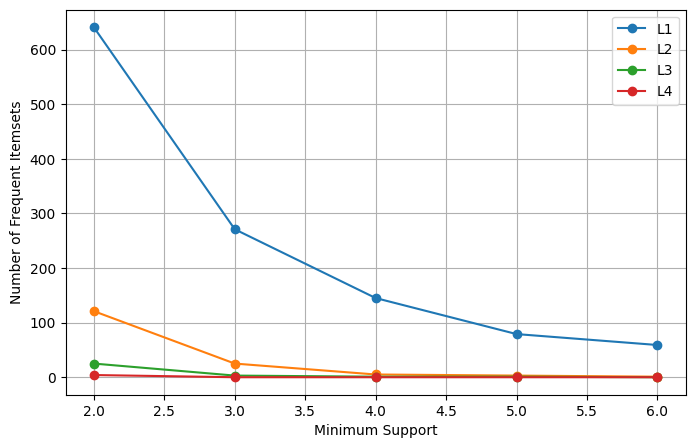

In [31]:
df_experiment.plot(
    x="Min Support",
    y=["L1", "L2", "L3", "L4"],
    marker="o",
    figsize=(8, 5)
)
plt.xlabel("Minimum Support")
plt.ylabel("Number of Frequent Itemsets")
plt.grid(True)
plt.show()

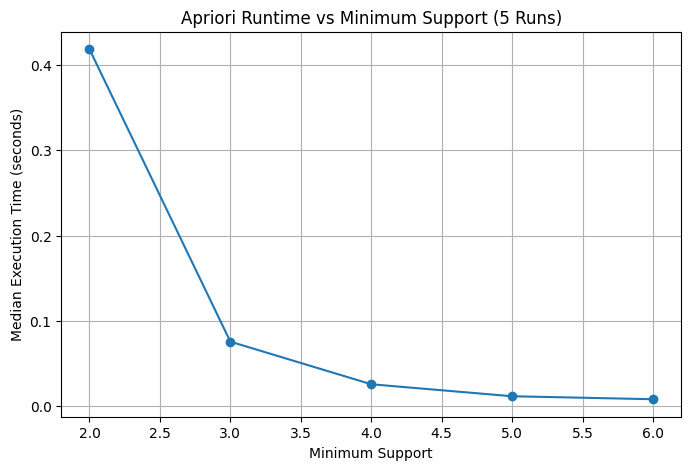

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_experiment["Min Support"],
    df_experiment["Median Time (s)"],
    marker="o"
)

plt.title("Apriori Runtime vs Minimum Support (5 Runs)")
plt.xlabel("Minimum Support")
plt.ylabel("Median Execution Time (seconds)")
plt.grid(True)
plt.show()

In [33]:
#scaleability tests  with different sizes
dataset_sizes = [100, 250, 500, 750, 1000]

shuffled_baskets = baskets.sample(frac=1, random_state=42)
scalability_results = []
for n in dataset_sizes:

    subset = shuffled_baskets.iloc[:n]
    times = []

    for repeat in range(5):

        start = time.perf_counter()
        result = apriori(subset, min_support)
        elapsed = time.perf_counter() - start

        times.append(elapsed)

    scalability_results.append({
        "Basket Count": n,
        "L1": len(result.get(1, {})),
        "L2": len(result.get(2, {})),
        "L3": len(result.get(3, {})),
        "Total": sum(len(x) for x in result.values()),
        "Median Time (s)": np.median(times)
    })

df_scalability = pd.DataFrame(scalability_results)

print(df_scalability.to_string(index=False))

 Basket Count  L1  L2  L3  Total  Median Time (s)
          100   2   0   0      2         0.001664
          250  31   3   0     34         0.002648
          500  98  10   0    108         0.012317
          750 176  17   2    195         0.034080
         1000 271  25   3    299         0.076929


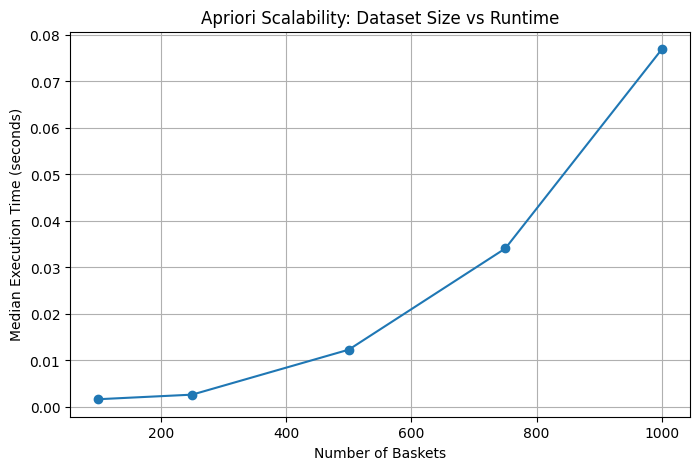

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_scalability["Basket Count"],
    df_scalability["Median Time (s)"],
    marker="o"
)

plt.title("Apriori Scalability: Dataset Size vs Runtime")
plt.xlabel("Number of Baskets")
plt.ylabel("Median Execution Time (seconds)")
plt.grid(True)

plt.show()